# Deep Learning - Winter Term 2026/2027

<hr style="border:2px solid gray">

### Exercise Sheet 02

<br>

# 4) Train MLP with nonlinear decision boundary in PyTorch

Until now, we used our own framework. From now on, we will use PyTorch throughout this semester (in fact, we will use it next semester as well). It is a ubiquitous and easy-to-use library that allows rapid prototyping of deep learning models. Chances are high, that you will use it in your professional life later. Therefore, we encourage you to get a good grasp of it as soon as possible. You will see that the interface is very similar to the framework you built yourself. Here is a relatively short tutorial about the backbones of PyTorch:

[https://youtu.be/nf-r9gnum7o?si=57TdegnhlFDuQ1Bg](https://youtu.be/nf-r9gnum7o?si=57TdegnhlFDuQ1Bg)

You can also use google colab for PyTorch (even with GPU support, which might be helpful for later exercise sheets).

Introduction to Colab
[https://colab.research.google.com](https://colab.research.google.com)

Tutorial 2: Introduction to PyTorch
[https://colab.research.google.com/github/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial2/Introduction_to_PyTorch.ipynb](https://colab.research.google.com/github/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial2/Introduction_to_PyTorch.ipynb)

But now, let's get to the action!

In [7]:
import random
import numpy as np
import matplotlib.pyplot as plt

In [8]:
# Import the pytorch library. You might need to install it.
# Import the pytorch library. You might need to install it.
import torch
from torch import nn

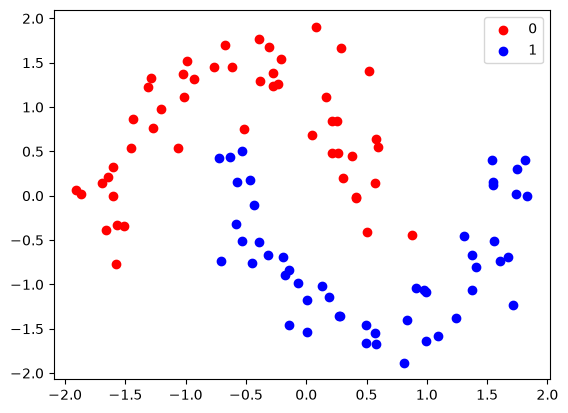

<Figure size 640x480 with 0 Axes>

In [9]:
# We provide you the dataset in .npz file. You just need to load it here.
dataset = np.load('2d_pcl_dataset.npz')
X, y = dataset['X'], dataset['y']

### Plot the data ###
X0 = X[y==0] # 50 2D points have label 0
X1 = X[y==1] # 50 2D points have label 1

y = np.expand_dims(y, axis=1)

def plot(X0, X1, fit_param=None):
    plt.scatter(X0[:,0], X0[:,1], color='red', label=0)
    plt.scatter(X1[:,0], X1[:,1], color='blue', label=1)
    
    plt.legend()
    plt.show()
    plt.clf()

plot(X0, X1)

In [10]:
# Create the MLP class

import torch


class MLP(torch.nn.Module):

    def __init__(self):
        super().__init__()
        # TODO: Create a network with nn.Sequential that is combination of linear layers
        # Again, you need to decide the size of the network, about the bias term and activation functions
        # self.layers = nn.Sequential(nn.Linear(....
        self.layers = nn.Sequential(
            torch.nn.Linear(2, 16),  # Input layer to hidden layer
            torch.nn.ReLU(),          # Activation function
            torch.nn.Linear(16, 8),   # Hidden layer to another hidden layer
            torch.nn.ReLU(),          # Activation function
            torch.nn.Linear(8, 1),    # Hidden layer to output layer
            torch.nn.Sigmoid()        # Activation function for binary classification
        )

    def forward(self, x):
        ''' forward pass '''
        return self.layers(x)


In [11]:
# Set fixed random number seed (for reproducibility)
torch.manual_seed(42)

In [12]:
# initialize the model
model = MLP()

# Look at the model and the number of parameters
print(model)
print("number of parameters", sum(p.numel() for p in model.parameters()))

MLP(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
    (5): Sigmoid()
  )
)
number of parameters 193


In [13]:
# TODO: Set the loss function. Which function makes sense for the problem at hand?
# criterion = nn.(your loss function here)
criterion = nn.BCELoss()  # Binary Cross Entropy Loss for binary classification


In [14]:
# TODO: Set the optimizer. Start with SGD in the beginning.
# Afterwards you can try different algorithms from the lecture
# and see how effective they are. Try also different learning rates
# to develop an intuition about the effect of it.
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)  # Stochastic Gradient Descent optimizer  


In [15]:
# Before starting the training we need to convert the data into a tensor
# Pytorch works **only** with tensors
X = torch.Tensor(X).float()
y = torch.Tensor(y).float()
print(X.dtype, y.dtype)

torch.float32 torch.float32


In [16]:
# Training loop

# Let the model know we are training
model.train()

# This time, we provide you the training loop.
# You have done it already in the previous exercise.
# You might still need to decide for the training length though.
# It is a hyperparameter and depends on other features of your network.
epochs = 1000 # TODO: change None with a reasonable number
for epoch in range(epochs):
    # Zero the gradients
    optimizer.zero_grad()
    
    # Forward pass
    y_hat = model(X)

    # Compute the loss
    loss = criterion(y_hat, y)

    # Backward pass
    loss.backward()

    # Weight update
    optimizer.step()

    # Print loss
    if epoch % 100 == 0: # TODO: change None with a reasonable number
        print(f'Loss after epoch {epoch} --> {loss.item()}')

print('Training completed')

Loss after epoch 0 --> 0.691885769367218
Loss after epoch 100 --> 0.6730294823646545
Loss after epoch 200 --> 0.6448280811309814
Loss after epoch 300 --> 0.6000000238418579
Loss after epoch 400 --> 0.5365249514579773
Loss after epoch 500 --> 0.46445977687835693
Loss after epoch 600 --> 0.39838889241218567
Loss after epoch 700 --> 0.3507269024848938
Loss after epoch 800 --> 0.322051465511322
Loss after epoch 900 --> 0.30489787459373474
Training completed


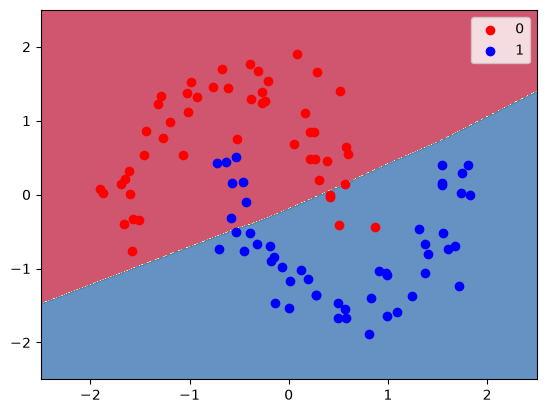

Accuracy: 88.99999856948853 %


<Figure size 640x480 with 0 Axes>

In [ ]:
# Plot model's performance

# Create numbers in a mesh to feed into the model
p = np.linspace(-2.5, 2.5, 500)
x_plot, y_plot = np.meshgrid(p, p)
X_plot = np.stack((x_plot, y_plot), axis=2).reshape(-1, 2)

# Feed the created numbers into the model
output = model(torch.Tensor(X_plot)).detach().numpy()
output = np.round(output).reshape(x_plot.shape[0], x_plot.shape[1])

plt.contourf(x_plot, y_plot, output, cmap=plt.cm.Spectral, alpha=0.8)

# # Following plots only the decision boundary
# plt.contour(x_plot, y_plot, output, [0.5],
#                   colors=('k',),
#                   linewidths=(3,))
# Plot the dots
plot(X0, X1)



Compare SGD and Adam with different learning rates and briefly describe the differences.

*Your answer:*